# Distribution Analysis
Distribution analysis is the process of studying how numerical values are spread across a dataset. It helps us understand the shape, center, spread, skewness, and possible outliers in a numerical feature.

## Normal Distribution
Definition
A normal distribution is a continuous, bell-shaped distribution in which values are symmetrically distributed around the mean. In a perfectly normal distribution, the mean, median, and mode are equal.
### Real-world example
- Adult heights within a suitable population and age group may be approximately normally distributed.
- Measurement errors from a stable measurement process may approximately follow a normal distribution.
### Business example
- Manufacturing measurements, such as the diameter of parts produced by a stable process, may follow an approximately normal distribution.
- Small random variations in product filling weights may be approximately normally distributed when the process is well controlled.
### AI/ML use case
Normality is important for some statistical methods and model assumptions. It can help with statistical inference, residual analysis in regression, and understanding standardized numerical features. However, not every Machine Learning algorithm requires normally distributed input features.

In [1]:
%mamba install pandas

mambajs 0.21.4

Specs: xeus-python, numpy, matplotlib, pillow, ipywidgets>=8.1.6, ipyleaflet, scipy, pandas
Channels: emscripten-forge-4x, conda-forge

Solving environment...
Solving took 3.968 seconds
  Name           Version  Build                Channel
--------------------------------------------------------------------
+ pandas         3.1.0    np23py313h124dbc7_0  emscripten-forge-4x
+ python-tzdata  2026.5   pyh5ded981_0         conda-forge
- pip            26.2.1   pyh145f28c_0         conda-forge


In [2]:
%mamba install seaborn

mambajs 0.21.4

Specs: xeus-python, numpy, matplotlib, pillow, ipywidgets>=8.1.6, ipyleaflet, scipy, pandas, seaborn
Channels: emscripten-forge-4x, conda-forge

Solving environment...
Solving took 2.598 seconds
  Name          Version  Build                Channel
-------------------------------------------------------------------
+ patsy         1.0.3    py313h1804a44_0      emscripten-forge-4x
+ seaborn       0.13.2   hd8ed1ab_3           conda-forge
+ seaborn-base  0.13.2   pyhd8ed1ab_3         conda-forge
+ statsmodels   0.15.0   np23py313h07ed413_0  emscripten-forge-4x


Mean: 50.19
Standard Deviation: 9.79


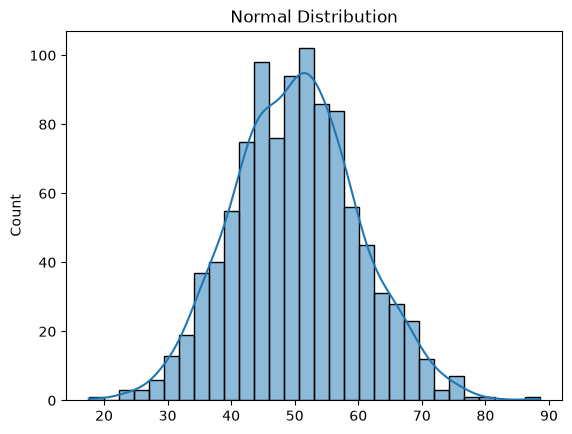

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

np.random.seed(42)

data = np.random.normal(
    loc=50,
    scale=10,
    size=1000
)

print("Mean:", round(np.mean(data), 2))
print("Standard Deviation:", round(np.std(data), 2))

sns.histplot(data, bins=30, kde=True)
plt.title("Normal Distribution")
plt.show()

### Explanation of the code
- np.random.normal() generates random values from a normal distribution.
- loc=50 sets the population mean to 50.
- scale=10 sets the population standard deviation to 10.
- size=1000 generates 1,000 observations.
- np.mean() and np.std() calculate the sample's mean and population-standard-deviation estimate, respectively.
- kde=True adds a smooth density curve to the histogram.

## Uniform Distribution
Definition
A uniform distribution is a distribution in which all outcomes within a specified range have equal probability in the continuous case. Its density is flat between the minimum and maximum values.
### Real-world example
- A random number generator that produces values uniformly between 0 and 1.
- The arrival time of a randomly selected point within a fixed time interval, assuming every moment in that interval is equally likely.
### Business example
- A simulation randomly assigns customer arrivals across a time interval when arrivals are deliberately modeled as uniformly distributed.
- A business simulation generates random discount values between 5% and 15%, with all values in that range equally likely.
### AI/ML use case
Uniform distributions are useful in random sampling, simulation, and initializing or searching model parameters over specified ranges. They also help analysts recognize when data is spread relatively evenly across a range.

Minimum: 10.19
Maximum: 49.99
Mean: 29.61


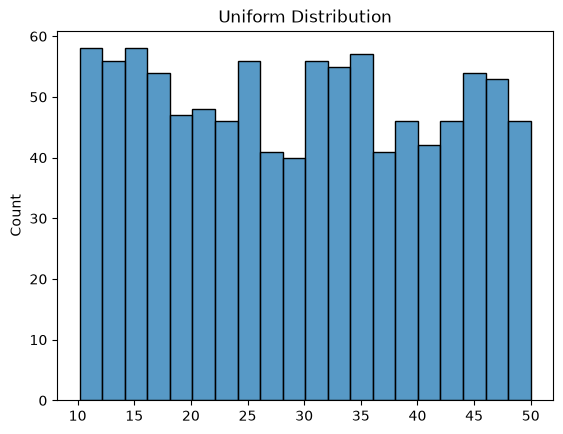

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

np.random.seed(42)

data = np.random.uniform(
    low=10,
    high=50,
    size=1000
)

print("Minimum:", round(data.min(), 2))
print("Maximum:", round(data.max(), 2))
print("Mean:", round(data.mean(), 2))

sns.histplot(data, bins=20)
plt.title("Uniform Distribution")
plt.show()

### Explanation of the code
- np.random.uniform() generates random numbers from a uniform distribution.
- low=10 and high=50 define the range.
- size=1000 generates 1,000 observations.
- min() and max() identify the smallest and largest observed values.
- mean() calculates the sample average, which should be near 30.
- sns.histplot() visualizes the frequency of values in different intervals.

## Skewness
Definition
Skewness measures the asymmetry of a numerical distribution. A positive value indicates right skew, a negative value indicates left skew, and a value near zero indicates little measured skewness.
### Real-world example
- Household income often has positive skew because a small number of people earn much more than the majority.
- Scores on a very easy test may have negative skew if most students score highly and only a few score low.
### Business example
- Customer spending often has right skew because a few customers place exceptionally large orders.
- Delivery times may have right skew because most deliveries arrive on time while a few experience substantial delays.
### AI/ML use case
Skewness helps determine whether a numerical feature may benefit from a transformation, such as a logarithm. It also helps explain why the mean and median differ and why some models may be sensitive to extreme values.

Skewness: 2.71


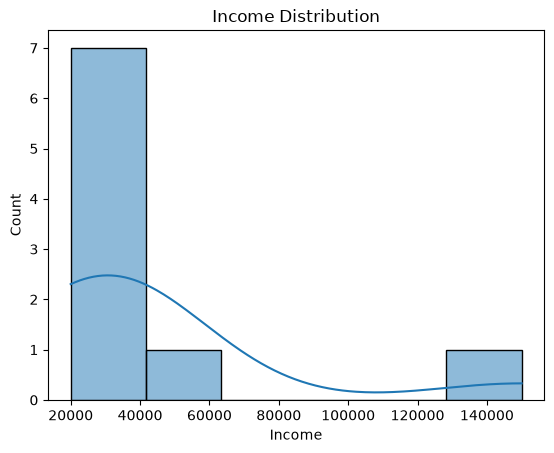

In [5]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.DataFrame({
    "Income": [20000, 22000, 25000, 27000, 30000,
               35000, 40000, 50000, 150000]
})

print("Skewness:", round(df["Income"].skew(), 2))

sns.histplot(df["Income"], bins=6, kde=True)
plt.title("Income Distribution")
plt.show()

### Explanation of the code
- df["Income"].skew() calculates the sample skewness.
- A positive value indicates right skew.
- The unusually high income of 150,000 stretches the distribution toward the right.
- sns.histplot() shows the distribution of income values.
- The skewness value depends on the sample and the convention used to calculate it; it is not a universal cutoff for identifying skewed data.

## Kurtosis
Definition
Kurtosis describes aspects of a distribution's tail behavior relative to a normal distribution. Pandas reports excess kurtosis, where a normal distribution has a value of zero; larger positive values can indicate heavier tails or greater sensitivity to extreme observations.
### Real-world example
- Daily investment returns may occasionally contain extreme changes that affect the distribution's tail behavior.
- Sensor readings may usually remain stable but occasionally contain unusually large deviations.
### Business example
- Insurance claim amounts may have heavy tails because a small number of claims are exceptionally expensive.
- Transaction amounts may have heavy tails when rare, high-value purchases occur alongside ordinary transactions.
### AI/ML use case
Kurtosis helps analysts investigate tail behavior and potential extreme observations. It can be useful in risk analysis, anomaly investigation, and evaluating whether a feature's distribution differs substantially from a normal distribution.

In [6]:
import pandas as pd

df = pd.DataFrame({
    "Returns": [
        -2, -1, 0, 0, 0, 1, 2, 3, -3, 20
    ]
})

print("Excess Kurtosis:",
      round(df["Returns"].kurt(), 2))

Excess Kurtosis: 8.11


### Explanation of the code
- df["Returns"].kurt() calculates the excess kurtosis.
- The unusually large value of 20 contributes to heavier tail behavior in this small example.
- Positive excess kurtosis indicates more tail weight or extreme-value sensitivity than the normal-distribution reference, though the precise shape depends on the entire distribution.
- Kurtosis alone does not tell you whether the distribution is left-skewed or right-skewed.

## Symmetric Distribution
Definition
A symmetric distribution has approximately the same shape on both sides of its center. In a perfectly symmetric distribution with a well-defined mean, the mean and median coincide, although the distribution does not have to be normal.
### Real-world example
- Measurement errors from a well-calibrated process may be approximately symmetric around zero.
- Some biological measurements may be approximately symmetric within a carefully defined population.
### Business example
- Small production variations around a target product weight may be approximately symmetric.
- Repeated measurement differences in a stable process may be distributed similarly above and below zero.
### AI/ML use case
Symmetry helps analysts understand whether the mean is a useful measure of center and whether a distribution has substantial asymmetry. Symmetry alone does not guarantee normality or suitability for a particular model.

Mean: 50.1
Median: 50.13
Skewness: 0.12


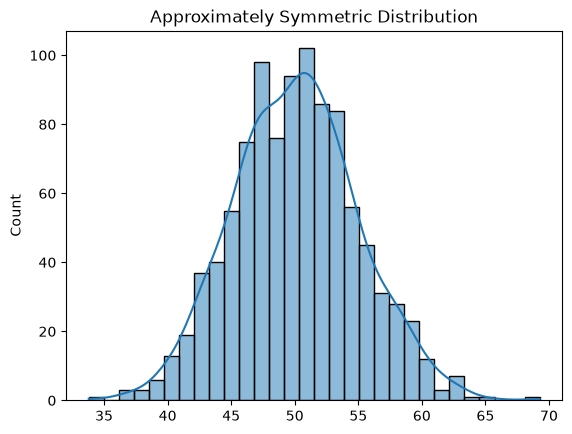

In [9]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

np.random.seed(42)

data = np.random.normal(50, 5, 1000)

print("Mean:", round(np.mean(data), 2))
print("Median:", round(np.median(data), 2))
print("Skewness:", round(pd.Series(data).skew(), 2))

sns.histplot(data, bins=30, kde=True)
plt.title("Approximately Symmetric Distribution")
plt.show()

### Explanation of the code
- np.random.normal() generates a symmetric, bell-shaped sample.
- np.mean() calculates the mean, while np.median() calculates the median.
- skew() measures asymmetry.
- A mean and median close to each other, along with skewness near zero, are consistent with approximate symmetry.
- A histogram helps confirm the shape visually.

## Left-Skewed Distribution (Negative Skew)
Definition
A left-skewed distribution has a longer or heavier tail toward lower values, while many observations are concentrated toward the higher end. Its skewness is negative, and the mean is often lower than the median.
### Real-world example
- Scores on a very easy examination may cluster near the maximum, with a few low scores creating a left tail.
- The age at which people retire in a particular group could show left skew if most retire around later ages but a smaller number retire much earlier.
### Business example
- Customer satisfaction ratings may cluster near the top of the scale, with a few very low ratings.
- Product quality scores may be high for most units, with a small number of poorly manufactured products producing a left tail.
### AI/ML use case
Recognizing negative skew helps analysts understand feature distributions, investigate low-end extreme values, and decide whether a transformation or robust summary is appropriate.

Mean: 90.27
Median: 93.13
Skewness: -1.87


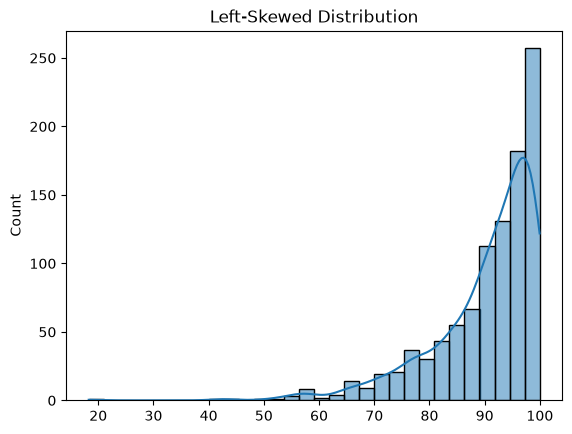

In [10]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

np.random.seed(42)

data = 100 - np.random.exponential(
    scale=10,
    size=1000
)

data = np.clip(data, 0, 100)

print("Mean:", round(np.mean(data), 2))
print("Median:", round(np.median(data), 2))
print("Skewness:", round(pd.Series(data).skew(), 2))

sns.histplot(data, bins=30, kde=True)
plt.title("Left-Skewed Distribution")
plt.show()

### Explanation of the code
- np.random.exponential() generates right-skewed positive values.
- Subtracting those values from 100 reverses the direction of the skew.
- np.clip() restricts scores to the range from 0 to 100.
- The mean is often below the median because lower scores extend the left tail.
- skew() measures the resulting asymmetry.
- Clipping can change the distribution's shape, so the output is illustrative rather than a perfect theoretical distribution.

## Right-Skewed Distribution (Positive Skew)
Definition
A right-skewed distribution has a longer or heavier tail toward higher values, while most observations are concentrated at the lower end. Its skewness is positive, and the mean is often higher than the median.
### Real-world example
- Personal income often has right skew because a relatively small number of people earn exceptionally high incomes.
- Waiting times may have right skew because most people wait briefly, while a few experience long delays.
### Business example
- Online order values may have right skew because most customers place small orders while a few make large purchases.
- Insurance claim amounts may have right skew because most claims are modest but some are very expensive.
### AI/ML use case
Right-skewed features may benefit from logarithmic transformations, robust scaling, or models that can handle skewed distributions. The best approach depends on the prediction task and model assumptions.

Mean: 972.51
Median: 686.78
Skewness: 1.87


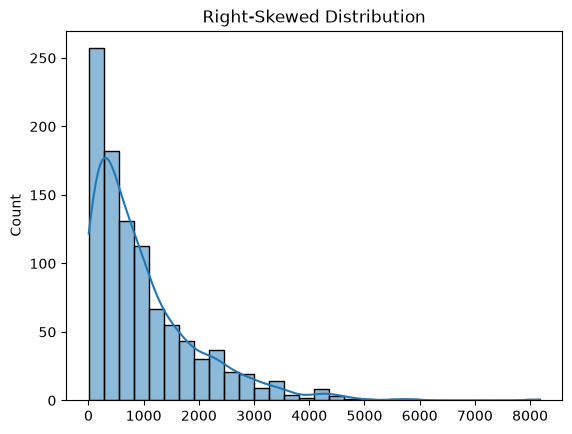

In [12]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

np.random.seed(42)

data = np.random.exponential(
    scale=1000,
    size=1000
)

print("Mean:", round(np.mean(data), 2))
print("Median:", round(np.median(data), 2))
print("Skewness:", round(pd.Series(data).skew(), 2))

sns.histplot(data, bins=30, kde=True)
plt.title("Right-Skewed Distribution")
plt.show()

### Explanation of the code
- np.random.exponential() creates a right-skewed distribution.
- scale=1000 sets the theoretical mean to 1,000.
- mean() and median() calculate the sample's center using two different measures.
- The mean is generally higher than the median because large values extend the right tail.
- skew() measures the distribution's asymmetry.
- The histogram should show many relatively small values and fewer large values.

## How to Analyze a Numerical Distribution
For each important numerical feature in your dataset, you should analyze five things: shape, center, spread, skewness, and outliers.
### A. Shape of distribution
Definition: The shape describes the overall pattern formed by the values in a distribution, including whether it is bell-shaped, flat, symmetric, skewed, or has multiple peaks.

### Real-world example: 
Students' marks may form a bell-shaped distribution, while household incomes may have a long right tail.

### Business example: 
Daily sales may show one main peak, while customer spending may have a long right tail.

### AI/ML use case: 
Distribution shape helps determine whether a feature needs further investigation or transformation and helps identify multiple customer or product groups.

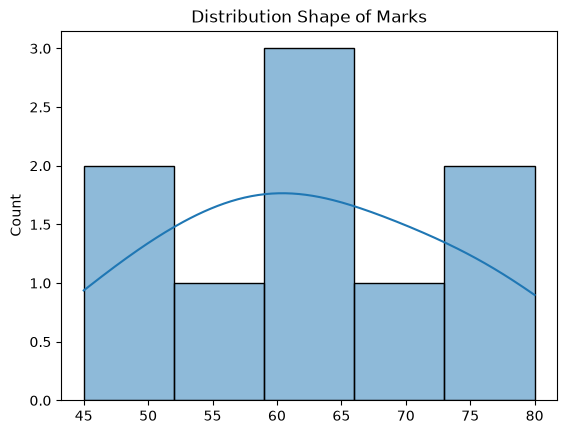

In [13]:
import seaborn as sns
import matplotlib.pyplot as plt

marks = [45, 50, 55, 60, 60, 65, 70, 75, 80]

sns.histplot(marks, bins=5, kde=True)
plt.title("Distribution Shape of Marks")
plt.show()

### Explanation of the code
- histplot() displays the frequency of values across intervals.
- bins=5 divides the values into five intervals.
- kde=True adds a smooth density estimate.
- The chart helps you determine whether the values appear symmetric, skewed, or concentrated in multiple regions.

### B. Center of distribution
Definition: The center represents a typical or central value in the dataset. Common measures are the mean, median, and mode.

### Real-world example: 
The average mark describes overall performance, while the median mark identifies the middle student's score after sorting the data.

### Business example: 
Average order value measures the mean purchase amount, while median order value represents the middle transaction amount.

### AI/ML use case: 
Measures of center help with feature summaries, missing-value imputation, normalization, and understanding typical model inputs.

In [14]:
import pandas as pd

sales = pd.Series([100, 120, 130, 150, 500])

print("Mean:", sales.mean())
print("Median:", sales.median())
print("Mode:", sales.mode().tolist())

Mean: 200.0
Median: 130.0
Mode: [100, 120, 130, 150, 500]


### Explanation of the code
- mean() calculates the arithmetic average.
- median() returns the middle value after sorting.
- mode() returns the most frequently occurring value or values.
- The mean is higher than the median because the value 500 pulls the average upward.
- An empty mode result means no value occurs more frequently than the others in this dataset.

## C. Spread of distribution
Definition: Spread describes how much the values vary around the center. Common measures include range, variance, standard deviation, and interquartile range (IQR).

### Real-world example: 
Two classrooms may have the same average marks, but one classroom may have much greater variation between students.

### Business example: 
Two stores may have the same average order value, but one may have more variation because it receives both very small and very large orders.

### AI/ML use case: 
Spread analysis supports feature scaling, comparison of variability, quality checks, and identifying numerical features that operate on very different scales.

In [16]:
import pandas as pd

data = pd.Series([10, 20, 30, 40, 50])

print("Range:", data.max() - data.min())
print("Variance:", data.var())
print("Standard Deviation:", round(data.std(), 2))
print("IQR:", data.quantile(0.75) - data.quantile(0.25))

Range: 40
Variance: 250.0
Standard Deviation: 15.81
IQR: 20.0


### Explanation of the code
- max() - min() calculates the range.
- var() calculates sample variance.
- std() calculates sample standard deviation.
- quantile(0.75) - quantile(0.25) calculates the IQR.
- The range uses only the minimum and maximum, whereas the IQR describes the middle 50% of the observations and is less affected by extreme values.

## D. Skewness
Definition: Skewness measures the asymmetry of a distribution. Positive skew indicates a right tail, negative skew indicates a left tail, and a value near zero indicates little measured asymmetry.

### Real-world example: 
Income often has positive skew, while marks on a very easy examination may have negative skew.

### Business example: 
Order values often have positive skew, while customer satisfaction scores can have negative skew when most ratings are high.

### AI/ML use case: 
Skewness helps identify features that may benefit from transformations and alerts analysts to distributions where the mean may not represent a typical value well.

In [17]:
import pandas as pd

data = pd.Series([10, 12, 13, 14, 15, 16, 18, 100])

print("Skewness:", round(data.skew(), 2))

Skewness: 2.79


### Explanation of the code
- skew() calculates sample skewness.
- The unusually high value of 100 creates a long right tail.
- The positive result indicates right skew.
- Skewness should be interpreted alongside a histogram and summary statistics, rather than as a standalone decision rule.

### E. Presence of outliers
Definition: Outliers are observations that differ substantially from the general pattern of a dataset. They can affect the mean, standard deviation, skewness, and the shape of the distribution.

### Real-world example: 
Most examination marks fall between 40 and 90, but one value is recorded as 900.

### Business example: 
Most orders are worth less than ₹5,000, but one transaction is worth ₹5,00,000.

### AI/ML use case: 
Outlier analysis helps identify data-quality problems and unusual events that may affect model training, particularly for algorithms sensitive to extreme values.

In [18]:
import pandas as pd

data = pd.Series([10, 12, 13, 14, 15, 16, 18, 100])

Q1 = data.quantile(0.25)
Q3 = data.quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

print("Lower bound:", lower)
print("Upper bound:", upper)
print("Potential outliers:",
      data[(data < lower) | (data > upper)].tolist())

Lower bound: 7.125
Upper bound: 22.125
Potential outliers: [100]


### Explanation of the code
- Q1 and Q3 calculate the first and third quartiles.
- IQR measures the spread of the middle 50% of the observations.
- The bounds are calculated using the 1.5 × IQR rule.
- The value 100 is flagged because it exceeds the upper bound.
- The flagged value should be investigated before deciding whether to correct, transform, remove, or retain it.